# how the debate names its wars

counting topics shows what a speech is about, not which side it takes. "Ukraine" appears in Lavrov's speech and in Zelenskyy's. this notebook reads how each speech describes the two wars of the decade, and asks five questions:

1. how did each country describe the war in Ukraine in 2026?
2. how has that wording changed since 2022, and who changed it?
3. how does each country describe Gaza?
4. do the countries that condemn one war condemn the other?
5. do the words match the votes?

**how the wording is read.** a fixed set of rules in [`analysis/wording.py`](https://github.com/jeremychia/unga-speeches/blob/main/src/unga_speeches/analysis/wording.py) gives each speech its strongest framing, and keeps the sentence that shows it, so every label can be checked. for Ukraine, blame means a sentence where Russia acts ("Russia has been waging a cruel war") or the war is called aggression or an invasion; wording that puts both countries on the same footing ("the war between Russia and Ukraine") is neutral. Gaza is read on two questions, so that both sides are measured: does the speech criticise Israel (calling it genocide, or criticising its conduct such as strikes, starvation or settlements), and does it blame Hamas or defend Israel (condemning Hamas or the 7 October attack, demanding that Hamas disarm or free the hostages, or affirming Israel's right to defend itself). a speech can do one, both or neither. merely naming the hostages does not count as taking a side.

**the two wars are read on different scales.** blaming Russia counts even a passing "Russia's war", while criticising Israel needs an act attributed to Israel, and the rules catch nearly all blame of Russia but only about half of criticism of Israel. so compare each war with itself, across years and countries, more than one war with the other.

**how well it reads.** the labels were checked against readers who never saw the rules: separate AI models, not people, each labelling speeches from the extracted sentences alone. the rules were corrected with three such checks, the last a reading of every 2026 speech, and then measured on a fresh sample of 80 speeches from 2022–2025 that no check had used. on that sample the Ukraine labels are almost always right, the Gaza genocide labels are reliable, and criticism of Israel is undercounted: the rules catch about half of critical speeches, missing criticism that never names Israel. the scores are at the end of this notebook, and `make wording` rebuilds every label from [`analysis/wording.py`](https://github.com/jeremychia/unga-speeches/blob/main/src/unga_speeches/analysis/wording.py).

**the texts change kind.** 2022–2024 are the UN's official records, 2025 is a transcript of the interpreters, and 2026 is mostly the text each delegation filed. year-to-year changes are large next to that, but small ones should be read with care.

In [1]:
import pathlib
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy import stats

from unga_speeches.analysis import wording
from unga_speeches.analysis.charts import (BLUE, BLUE_INK, HONEY, INK, INK_2, MUTED, NOT_RAISED, RAMP, ROSE, ROSE_INK, SQUARE, SURFACE,
                                           finalize, legend, show, style, world, world_map)

style()
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
ref = pd.read_csv(ROOT / "reference/delegations.csv")
REGION = dict(zip(ref.iso3, ref.m49_region))
STATES = set(ref.iso3.dropna())

# every speech since the war in Ukraine began, labelled by the rules in analysis/wording.py (the same table `make wording` writes)
classified = wording.classify()
ukr = classified.rename(columns={"ukraine": "cls", "ukraine_evidence": "evidence"})
gz = classified[classified.year >= wording.FIRST_YEAR["gaza"]].rename(columns={"gaza": "cls", "gaza_evidence": "evidence"}).reset_index(drop=True)
texts = pd.read_parquet(ROOT / "data/output/speeches.parquet", columns=["year", "iso3", "delegation", "speaker_name", "speaker_title", "english_text_clean"])
texts = texts[(texts.year >= wording.FIRST_YEAR["ukraine"]) & (texts.english_text_clean.str.split().str.len() >= wording.MIN_WORDS)]
votes = pd.read_csv(ROOT / "reference/un_votes.csv").pivot(index="iso3", columns="resolution", values="vote")

BLAMES, NO_BLAME, RUSSIAS, SILENT = wording.UKRAINE_CLASSES
GENOCIDE, CONDUCT, BOTH, ISRAELS_SIDE, NEITHER, NO_GAZA = wording.GAZA_CLASSES
CRITICAL = [GENOCIDE, CONDUCT, BOTH]  # speeches that criticise Israel, whatever else they say
SIDES = [BOTH, ISRAELS_SIDE]  # speeches that blame Hamas or defend Israel, whatever else they say
# one colour per framing, the same in every chart: blue for blame, light blue for wording that blames no one, rose for Russia's framing
UK = {BLAMES: BLUE_INK, NO_BLAME: "#8fcdf0", RUSSIAS: ROSE, SILENT: NOT_RAISED}
# pinks criticise Israel, honey blames Hamas or defends Israel, violet does both, light blue blames neither side (as for Ukraine)
GZ = {GENOCIDE: ROSE_INK, CONDUCT: "#d0878c", BOTH: "#9793e6", ISRAELS_SIDE: HONEY, NEITHER: "#8fcdf0", NO_GAZA: NOT_RAISED}
YEARS = [2022, 2023, 2024, 2025, 2026]
print(pd.crosstab(ukr.cls, ukr.year).loc[list(UK)])
print(pd.crosstab(gz.cls, gz.year).loc[list(GZ)])


def say(df, n=4, prefer=("USA", "CHN", "IND", "BRA", "FRA", "GBR", "DEU", "TUR", "ZAF", "JPN", "SAU", "IDN", "NGA", "MEX", "RUS", "ISR", "PSE"), col="evidence"):
    """print up to n of the sentences behind a group of speeches, large or central countries first, with who said them."""
    df = df.assign(rank=df.iso3.map(lambda i: prefer.index(i) if i in prefer else len(prefer))).sort_values(["rank", "delegation"])
    for r in df.head(n).itertuples():
        print(textwrap.fill(f"“{getattr(r, col)}”", 110, initial_indent="  ", subsequent_indent="   "))
        print(f"     — {r.speaker_name}, {r.speaker_title}, {r.delegation}\n")

year                                  2022  2023  2024  2025  2026
cls                                                               
blames Russia or calls it aggression    66    55    47    41    39
names Ukraine but blames no one         74    70    70    67    39
uses Russia's framing                    3     2     5     3     3
does not mention Ukraine                51    68    75    84   113
year                                2024  2025  2026
cls                                                 
calls it genocide                     26    43    13
criticises Israel's conduct           19     9    22
criticises both sides                  6     7     9
blames Hamas or defends Israel        23    19     9
blames neither side                   66    76    56
does not mention Gaza or Palestine    57    41    85


## 1. how did each country describe the war in Ukraine in 2026?

each country is coloured by the strongest framing in its speech. the bars count the speeches in each framing.

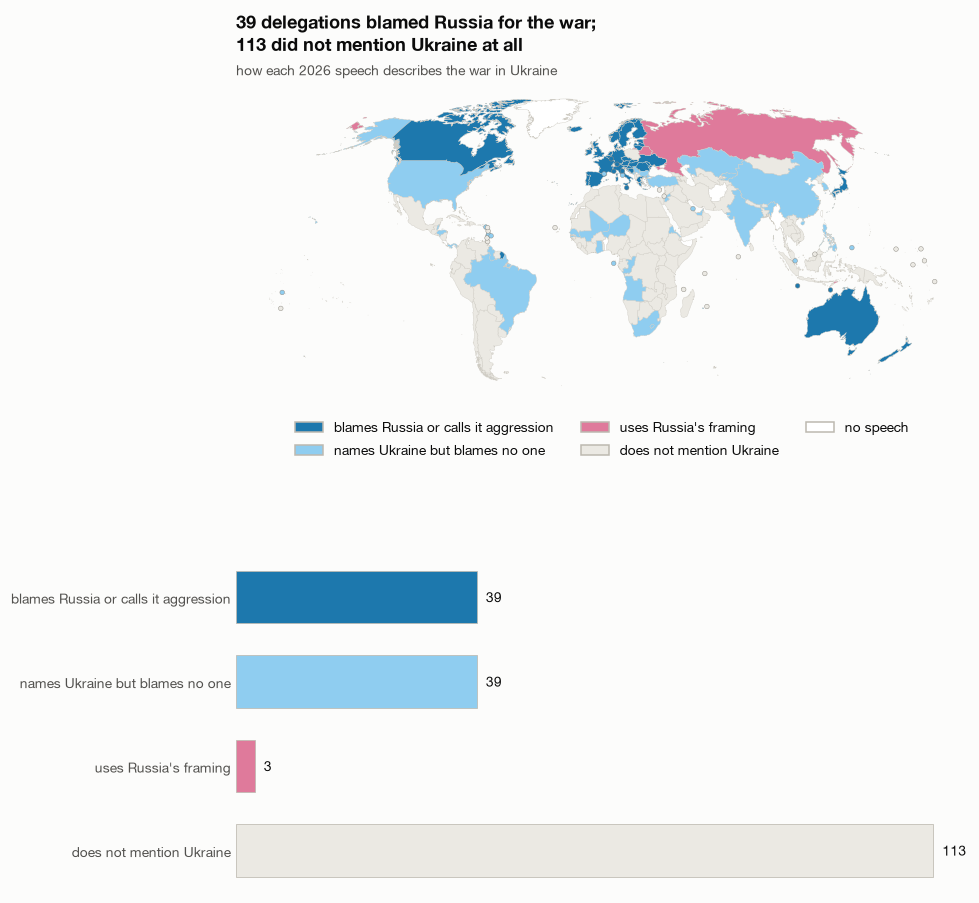

In [2]:
u26 = ukr[ukr.year == 2026]
counts = u26.cls.value_counts().reindex(list(UK), fill_value=0)

fig, (ax, bx) = plt.subplots(2, 1, figsize=SQUARE, gridspec_kw={"height_ratios": [1.7, 1]})
world_map(ax, {r.iso3: UK[r.cls] for r in u26.itertuples() if r.iso3 in STATES})
finalize(ax, f"{counts[BLAMES]} delegations blamed Russia for the war;\n{counts[SILENT]} did not mention Ukraine at all",
         "how each 2026 speech describes the war in Ukraine")
# the legend sits under the map; white is a country that gave no speech, or none long enough to read
from matplotlib.patches import Patch
from unga_speeches.analysis.charts import NO_SPEECH
ax.legend(handles=[Patch(facecolor=c, edgecolor="#bdb9b0", label=label) for label, c in list(UK.items()) + [("no speech", NO_SPEECH)]],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False, fontsize=9)
bx.barh(range(len(UK)), counts.values, color=list(UK.values()), edgecolor="#bdb9b0", linewidth=0.5, height=0.62)
for y, (label, n) in enumerate(counts.items()):
    bx.text(n + 1.5, y, f"{n}", va="center", fontsize=9, color=INK)
bx.set_yticks(range(len(UK)), list(UK), fontsize=9); bx.invert_yaxis(); bx.set_xticks([]); bx.tick_params(length=0)
for side in ("left", "bottom"):
    bx.spines[side].set_visible(False)
plt.tight_layout(); show(fig, "w1_ukraine_map")

**what they said.** the sentence behind each label, for a few countries in each framing.

In [3]:
for cls in [BLAMES, NO_BLAME, RUSSIAS]:
    group = u26[u26.cls == cls]
    print(f"{cls.upper()} ({len(group)})\n")
    say(group, n=4)

BLAMES RUSSIA OR CALLS IT AGGRESSION (39)

  “In Ukraine, for almost five years now, Russia has been waging a cruel war on civilians.”
     — Emmanuel Macron, President, France

  “I was in Kyiv last month, and it gave me a glimpse of life under Russian attack.”
     — Andy Burnham, Prime Minister, United Kingdom of Great Britain and Northern Ireland

  “Today, Germany is the largest supporter of Ukraine in its defence against Russian aggression.”
     — Johann Wadephul, Federal Minister for Foreign Affairs, Germany

  “Russia’s aggression against Ukraine is the most obvious example.”
     — Takaichi Sanae, Prime Minister, Japan

NAMES UKRAINE BUT BLAMES NO ONE (39)

  “We're working very closely with the leaders of Russia and Ukraine, and we will get that one done.”
     — Donald Trump, President, United States of America

  “On Ukraine, President XI Jinping has put forward four points on what must be done, which are the
   fundamental guidance for China in playing a continued constru

## 2. how has the wording changed since 2022, and who changed it?

each column is one debate. each block is the speeches with one framing, and the bands follow the same delegation from one debate to the next, coloured by where it came from.

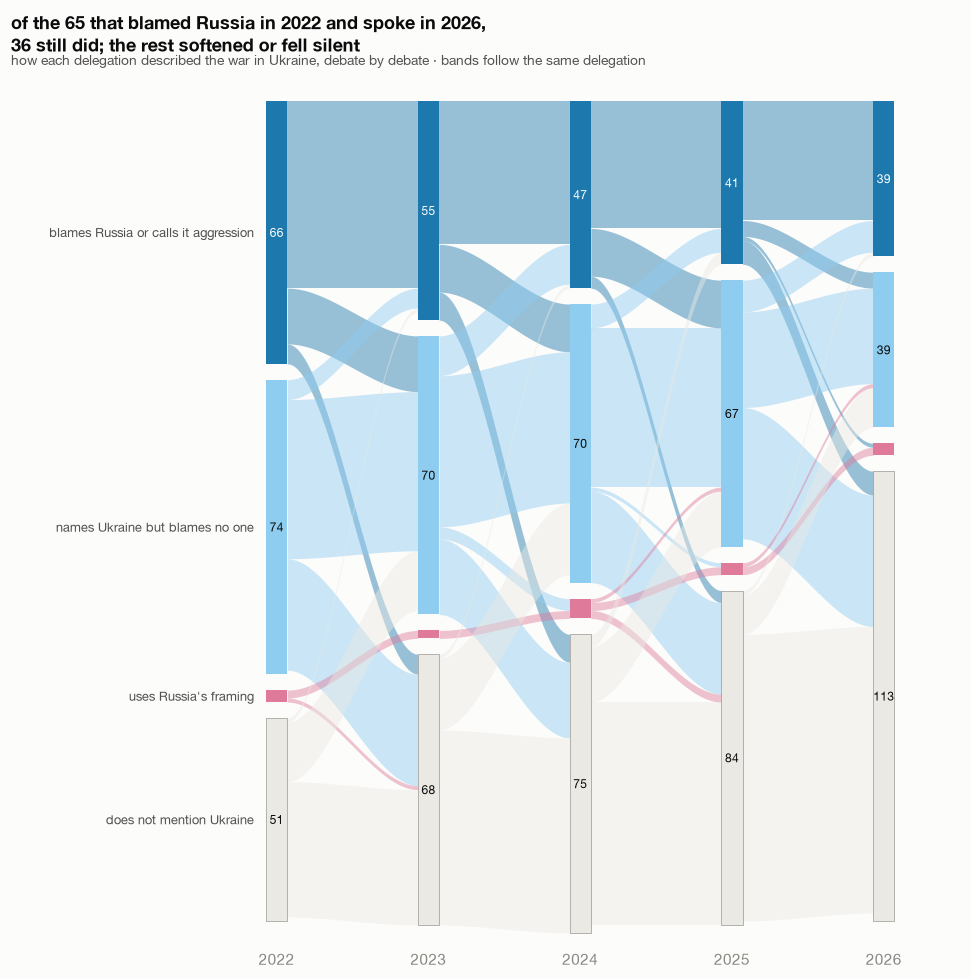

the 2022 blamers in 2026: {'blames Russia or calls it aggression': 36, 'names Ukraine but blames no one': 10, "uses Russia's framing": 1, 'does not mention Ukraine': 18} 

names Ukraine but blames no one in 2026 (10): Barbados, Belize, Bulgaria, Ghana, Montenegro, Palau, President of the
General Assembly (opening), Serbia, Singapore, United States of America 

does not mention Ukraine in 2026 (18): Albania, Botswana, Chile, Comoros, Cyprus, Djibouti, Dominica, Dominican
Republic, Ecuador, Fiji, Georgia, Grenada, Marshall Islands, Micronesia (Federated States of), North Macedonia, Poland,
Switzerland, Uruguay 



In [4]:
cls_in = {y: dict(zip(ukr[ukr.year == y].iso3, ukr[ukr.year == y].cls)) for y in YEARS}
ORDER, GAP_ROWS, WIDTH = list(UK), 4, 0.14


def blocks(year):
    """where each framing's block sits in a year's column: (top, height), stacked in a fixed order with a gap between."""
    n = pd.Series(cls_in[year]).value_counts().reindex(ORDER, fill_value=0)
    top, out = 0, {}
    for c in ORDER:
        out[c] = (top, n[c])
        top += n[c] + GAP_ROWS
    return out


def ribbon(ax, x0, x1, top0, top1, h, colour):
    """a band h countries thick from one column's block to the next, along a smooth s-curve."""
    t = np.linspace(0, 1, 40)
    e = 3 * t**2 - 2 * t**3
    x = x0 + (x1 - x0) * t
    ax.fill_between(x, top0 + (top1 - top0) * e, top0 + h + (top1 - top0) * e, color=colour, alpha=0.45, lw=0)


fig, ax = plt.subplots(figsize=SQUARE)
pos = {y: blocks(y) for y in YEARS}
for i, (a, b) in enumerate(zip(YEARS, YEARS[1:])):
    both = [iso for iso in cls_in[a] if iso in cls_in[b]]
    pairs = pd.Series([(cls_in[a][iso], cls_in[b][iso]) for iso in both]).value_counts()
    out_off = {c: pos[a][c][0] for c in ORDER}
    in_off = {c: pos[b][c][0] for c in ORDER}
    # bands leave each block in the order of the block they go to, and arrive in the order of the block they came from
    for src in ORDER:
        for dst in ORDER:
            n = pairs.get((src, dst), 0)
            if n:
                ribbon(ax, i + WIDTH / 2, i + 1 - WIDTH / 2, out_off[src], in_off[dst], n, UK[src])
                out_off[src] += n
                in_off[dst] += n
for i, y in enumerate(YEARS):
    for c in ORDER:
        top, h = pos[y][c]
        ax.add_patch(Rectangle((i - WIDTH / 2, top), WIDTH, h, facecolor=UK[c], edgecolor="#8d8a82" if c == SILENT else "none", lw=0.4))
        if h >= 6:
            ax.text(i, top + h / 2, str(h), ha="center", va="center", fontsize=8, color=SURFACE if c == BLAMES else INK)
for c in ORDER:
    top, h = pos[YEARS[0]][c]
    ax.text(-WIDTH / 2 - 0.08, top + h / 2, c, ha="right", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(-1.75, len(YEARS) - 0.5); ax.set_ylim(max(t + h for t, h in pos[YEARS[0]].values()) + 6, -4)
ax.set_xticks(range(len(YEARS)), YEARS); ax.set_yticks([]); ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)

blamed22 = [iso for iso, c in cls_in[2022].items() if c == BLAMES and iso in cls_in[2026]]
still = sum(cls_in[2026][iso] == BLAMES for iso in blamed22)
finalize(ax, f"of the {len(blamed22)} that blamed Russia in 2022 and spoke in 2026,\n{still} still did; the rest softened or fell silent",
         "how each delegation described the war in Ukraine, debate by debate · bands follow the same delegation")
plt.tight_layout(); show(fig, "w2_ukraine_flows")

# where the 2022 blamers went, and who they are
went = pd.Series({iso: cls_in[2026][iso] for iso in blamed22}).value_counts().reindex(ORDER, fill_value=0)
print("the 2022 blamers in 2026:", went[went > 0].to_dict(), "\n")
names = ukr.drop_duplicates("iso3").set_index("iso3").delegation
for c in [NO_BLAME, SILENT]:
    who = sorted(names[iso] for iso in blamed22 if cls_in[2026][iso] == c)
    print(textwrap.fill(f"{c} in 2026 ({len(who)}): " + ", ".join(who), 120), "\n")

one speech in the "does not mention Ukraine" group still condemns Russia: Poland's in 2026 speaks of Russia's "open aggression" and its "attacks on ports and ships transporting grain" without naming Ukraine. it is the only such case from 2022 to 2026.

## 3. how does each country describe Gaza?

each country is coloured by which side its speech criticises: pinks criticise Israel, honey blames Hamas or defends Israel, violet does both, and light blue does neither. the 2023 debate came before 7 October, so the bars start in 2024. criticism of Israel that names no actor is often missed, so the pink and violet shares are a floor (see how well the rules read, at the end); the genocide shares are reliable.

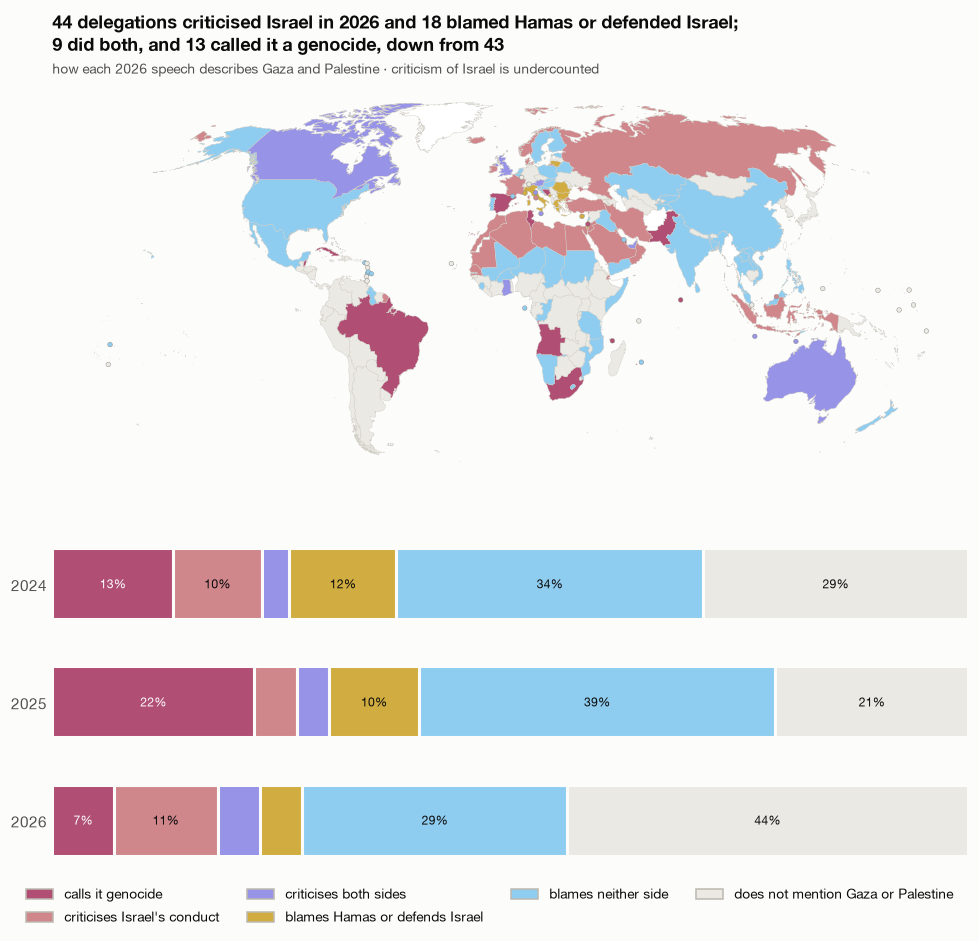

                                    2024  2025  2026
cls                                                 
calls it genocide                     26    43    13
criticises Israel's conduct           19     9    22
criticises both sides                  6     7     9
blames Hamas or defends Israel        23    19     9
blames neither side                   66    76    56
does not mention Gaza or Palestine    57    41    85


In [5]:
g = {y: gz[gz.year == y] for y in (2024, 2025, 2026)}
g26 = g[2026]
n26 = g26.cls.value_counts().reindex(list(GZ), fill_value=0)
n25 = g[2025].cls.value_counts().reindex(list(GZ), fill_value=0)

fig, (ax, bx) = plt.subplots(2, 1, figsize=SQUARE, gridspec_kw={"height_ratios": [1.7, 1]})
world_map(ax, {r.iso3: GZ[r.cls] for r in g26.itertuples() if r.iso3 in STATES})
finalize(ax, f"{n26[CRITICAL].sum()} delegations criticised Israel in 2026 and {n26[SIDES].sum()} blamed Hamas or defended Israel;\n"
             f"{n26[BOTH]} did both, and {n26[GENOCIDE]} called it a genocide, down from {n25[GENOCIDE]}",
         "how each 2026 speech describes Gaza and Palestine · criticism of Israel is undercounted")

# the same framings in each debate since the war began, as shares of the speeches
share = pd.DataFrame({y: g[y].cls.value_counts(normalize=True).reindex(list(GZ), fill_value=0) for y in g}).T
left = np.zeros(len(share))
for c in GZ:
    bx.barh([str(y) for y in share.index], share[c], left=left, color=GZ[c], edgecolor=SURFACE, linewidth=2, height=0.6, label=c)
    for k, (l, v) in enumerate(zip(left, share[c])):
        if v >= 0.06:
            bx.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=8, color=SURFACE if c == GENOCIDE else INK)
    left += share[c].values
bx.invert_yaxis(); bx.set_xlim(0, 1); bx.set_xticks([]); bx.tick_params(length=0)
for side in ("left", "bottom"):
    bx.spines[side].set_visible(False)
legend(fig, [(c, GZ[c]) for c in GZ])
plt.tight_layout(rect=(0, 0.06, 1, 1)); show(fig, "w3_gaza_map")

print(pd.DataFrame({y: g[y].cls.value_counts().reindex(list(GZ), fill_value=0) for y in g}).to_string())

In [6]:
for cls, col in [(GENOCIDE, "evidence"), (CONDUCT, "evidence"), (BOTH, "evidence"), (ISRAELS_SIDE, "side_evidence")]:
    group = g26[g26.cls == cls]
    print(f"{cls.upper()} ({len(group)})\n")
    say(group, n=4, col=col)
print(f"CRITICISES BOTH SIDES: what they said about Hamas or Israel's defence\n")
say(g26[g26.cls == BOTH], n=4, col="side_evidence")

CALLS IT GENOCIDE (13)

  “Generations of Palestinians will carry the pain and trauma left by the genocide of women and children
   perpetrated by the Netanyahu government in Gaza.”
     — Luiz Inácio Lula Da Silva, President, Brazil

  “The State of Israel’s continued violations of international and humanitarian law constitute genocide, and
   we remain steadfast in our view that the international community must act decisively to end this impunity.”
     — Ronald Ozzy Lamola, Minister for International Relations and Cooperation, South Africa

  “This is following long decades of historic injustice, uprooting asylum seeking occupation and the
   deprivation of its basic right to self-determination, freedom and independence in the Gaza Strip, our
   people are being subjected at the hands of the Israeli occupation forces to killing, destruction,
   starvation and attempts at displacement, as well as a genocidal war that has created an unprecedented
   humanitarian catastrophe.”
     — M

## 4. do the countries that condemn one war condemn the other?

each cell counts the 2026 speeches with one framing of Ukraine and one of Gaza. the Gaza columns run from criticising Israel, through criticising both sides, to blaming Hamas or defending Israel, and blaming neither. the two wars are read on different scales (see the top), so a cell describes what the rules found, not a judgement of consistency. the table below tests, debate by debate, whether blaming Russia goes with either side on Gaza.

**no consistent link.** in 2024 and 2025, blaming Russia made no clear difference to whether a country criticised Israel; in 2026 the link is borderline and does not pass the stricter bar for running several tests (p below 0.05 ÷ 3). blaming Russia goes clearly with blaming Hamas or defending Israel, in every debate (odds ratios of 10 to 18): most speeches doing either are European, as the regions below show. the tests are weak, with few countries in some cells, and the rules miss about half of criticism of Israel in earlier years. the regions printed below show who sits in each group.

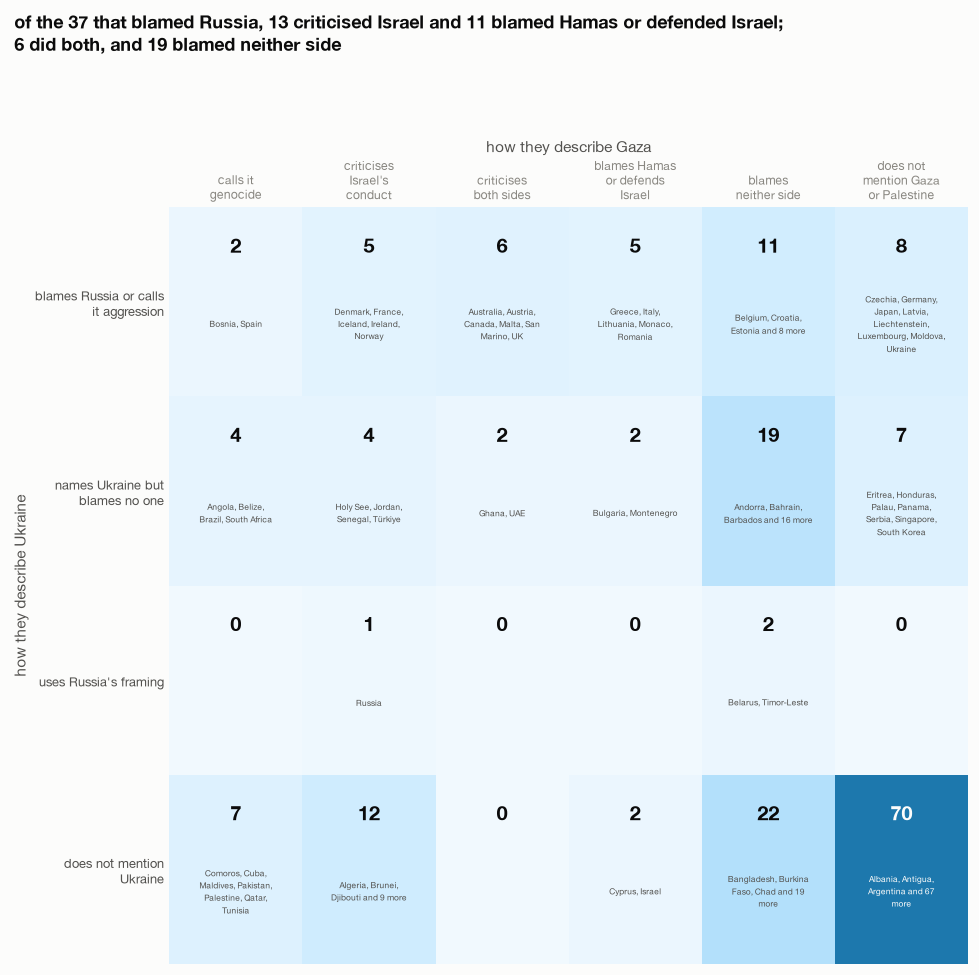

                                   blame Russia and this side  blame Russia only  this side only  neither  odds ratio  p (Fisher)
Gaza side                    year                                                                                                
criticise Israel             2024                           8                 38              43      104        0.51       0.128
                             2025                          12                 28              46      105        0.98       1.000
                             2026                          13                 24              30      124        2.24       0.050
blame Hamas or defend Israel 2024                          22                 24               7      140       18.33       0.000
                             2025                          16                 24               9      142       10.52       0.000
                             2026                          11                 26          

In [7]:
both = ukr[["year", "iso3", "delegation", "cls"]].merge(gz[["year", "iso3", "cls"]], on=["year", "iso3"], suffixes=("_ukr", "_gaza"))
b26 = both[(both.year == 2026) & both.iso3.isin(STATES)]
rows, cols = list(UK), list(GZ)
grid = pd.crosstab(b26.cls_ukr, b26.cls_gaza).reindex(index=rows, columns=cols, fill_value=0)

fig, ax = plt.subplots(figsize=SQUARE)
ax.imshow(grid.values, cmap=RAMP, vmin=0, vmax=grid.values.max(), aspect="auto")
SHORT = {"United Kingdom of Great Britain and Northern Ireland": "UK", "United States of America": "US", "Bosnia and Herzegovina": "Bosnia",
         "Brunei Darussalam": "Brunei", "Democratic Republic of the Congo": "DR Congo", "Russian Federation": "Russia", "Syrian Arab Republic": "Syria",
         "United Republic of Tanzania": "Tanzania", "Lao People's Democratic Republic": "Laos", "Republic of Korea": "South Korea",
         "Democratic People's Republic of Korea": "North Korea", "Saint Vincent and the Grenadines": "St Vincent", "Saint Kitts and Nevis": "St Kitts",
         "Antigua and Barbuda": "Antigua", "Sao Tome and Principe": "São Tomé", "Central African Republic": "CAR", "Trinidad and Tobago": "Trinidad",
         "Dominican Republic": "Dominican Rep.", "Papua New Guinea": "PNG", "Republic of Moldova": "Moldova", "Equatorial Guinea": "Eq. Guinea", "United Arab Emirates": "UAE", "State of Palestine": "Palestine"}  # fmt: skip
short = lambda n: SHORT.get(n, n.split(" (")[0])
ALL_UP_TO = 10  # cells this small list every country; bigger ones show a few and a count
for i, r in enumerate(rows):
    for j, c in enumerate(cols):
        who = sorted(short(n) for n in b26[(b26.cls_ukr == r) & (b26.cls_gaza == c)].delegation)
        n = grid.at[r, c]
        dark = n > grid.values.max() * 0.6
        names = ", ".join(who) if n <= ALL_UP_TO else ", ".join(who[:3]) + f" and {n - 3} more"
        ax.text(j, i - 0.3, str(n), ha="center", va="center", fontsize=13, fontweight="bold", color=SURFACE if dark else INK)
        if n:
            ax.text(j, i + 0.12, textwrap.fill(names, 20), ha="center", va="center", fontsize=5.5, linespacing=1.25, color=SURFACE if dark else INK_2)
ax.set_yticks(range(len(rows)), [textwrap.fill(r, 22) for r in rows], fontsize=8.5)
ax.set_xticks(range(len(cols)), [textwrap.fill(c, 13) for c in cols], fontsize=8)
ax.xaxis.tick_top(); ax.tick_params(length=0)
ax.set_ylabel("how they describe Ukraine"); ax.set_xlabel("how they describe Gaza"); ax.xaxis.set_label_position("top")
for s in ax.spines.values():
    s.set_visible(False)
blamed = grid.loc[BLAMES]
fig.suptitle(f"of the {blamed.sum()} that blamed Russia, {blamed[CRITICAL].sum()} criticised Israel and {blamed[SIDES].sum()} blamed Hamas or defended Israel;\n"
             f"{blamed[BOTH]} did both, and {blamed[[NEITHER, NO_GAZA]].sum()} blamed neither side",
             x=0.02, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.93)); show(fig, "w4_both_wars")

# is blaming russia linked to taking either side on gaza? one 2x2 test per debate and side
tests = []
for side, classes in [("criticise Israel", CRITICAL), ("blame Hamas or defend Israel", SIDES)]:
    for y in (2024, 2025, 2026):
        d = both[(both.year == y) & both.iso3.isin(STATES)]
        t = pd.crosstab(d.cls_ukr == BLAMES, d.cls_gaza.isin(classes)).reindex(index=[True, False], columns=[True, False], fill_value=0)
        odds, p = stats.fisher_exact(t.values)
        tests.append({"Gaza side": side, "year": y, "blame Russia and this side": t.at[True, True], "blame Russia only": t.at[True, False],
                      "this side only": t.at[False, True], "neither": t.at[False, False], "odds ratio": odds, "p (Fisher)": p})
print(pd.DataFrame(tests).set_index(["Gaza side", "year"]).round({"odds ratio": 2, "p (Fisher)": 3}).to_string(), "\n")

# who sits where in 2026, by UN region
b26 = b26.assign(region=b26.iso3.map(REGION))
print("blames Russia, by region:", b26[b26.cls_ukr == BLAMES].region.value_counts().to_dict())
print("criticises Israel, by region:", b26[b26.cls_gaza.isin(CRITICAL)].region.value_counts().to_dict())
print("blames Hamas or defends Israel, by region:", b26[b26.cls_gaza.isin(SIDES)].region.value_counts().to_dict())

**speakers who make the comparison themselves.**

In [8]:
# speakers who name the comparison themselves
pairing = texts[texts.year == 2026]
pairing = pairing.assign(evidence=pairing.english_text_clean.map(
    lambda t: next((s for s in wording._sentences(t) if wording.UKRAINE.search(s) and wording.GAZA.search(s) and len(s.split()) <= 70), "")))
pairing = pairing[pairing.evidence.ne("")]
print(f"sentences that name Ukraine and Gaza or Palestine together in 2026: {len(pairing)}\n")
say(pairing, n=6)

sentences that name Ukraine and Gaza or Palestine together in 2026: 18

  “From Gaza to Ukraine and Russia, from Myanmar to Darfur, from Iran to Lebanon, 250,000 people have lost
   their lives.”
     — Recep Tayyip Erdoğan, President, Türkiye

  “From what we have observed, we do not discern encouraging signs regarding the likelihood of reaching any
   peace agreement in the near future in the wars between Russia and Ukraine, in the Israeli-Palestinian
   conflict in the Middle East and in the Persian Gulf.”
     — João Manuel Gonçalves Lourenço, President, Angola

  “My friends, the scale of human tragedy is mounting, and whether it is in Gaza or the West Bank or Lebanon,
   or Yemen or Sudan or Ukraine or elsewhere.”
     — Mia Amor Mottley, Prime Minister, Barbados

  “The strengthening of authoritarian populism, the aggression against Ukraine, the suffering in Gaza, the war
   in the Gulf region, the catastrophic situation in Sudan and other flashpoints have brought humanity into 

## 5. do the words match the votes?

General Assembly votes on each war, set against the speeches that followed. the votes are in [`reference/un_votes.csv`](https://github.com/jeremychia/unga-speeches/blob/main/reference/un_votes.csv), which `make votes` rebuilds from the vote tables Wikipedia transcribes from the UN's records, and refuses to write unless the counts match the official totals. the March 2022 list also matches the UN's voting record country by country.

**Ukraine.** [ES-11/1](https://digitallibrary.un.org/record/3959039) in March 2022, and [ES-11/7](https://digitallibrary.un.org/record/4076672) in February 2025, when the United States voted against a resolution backed by Ukraine and Europe, each against the speeches that September.

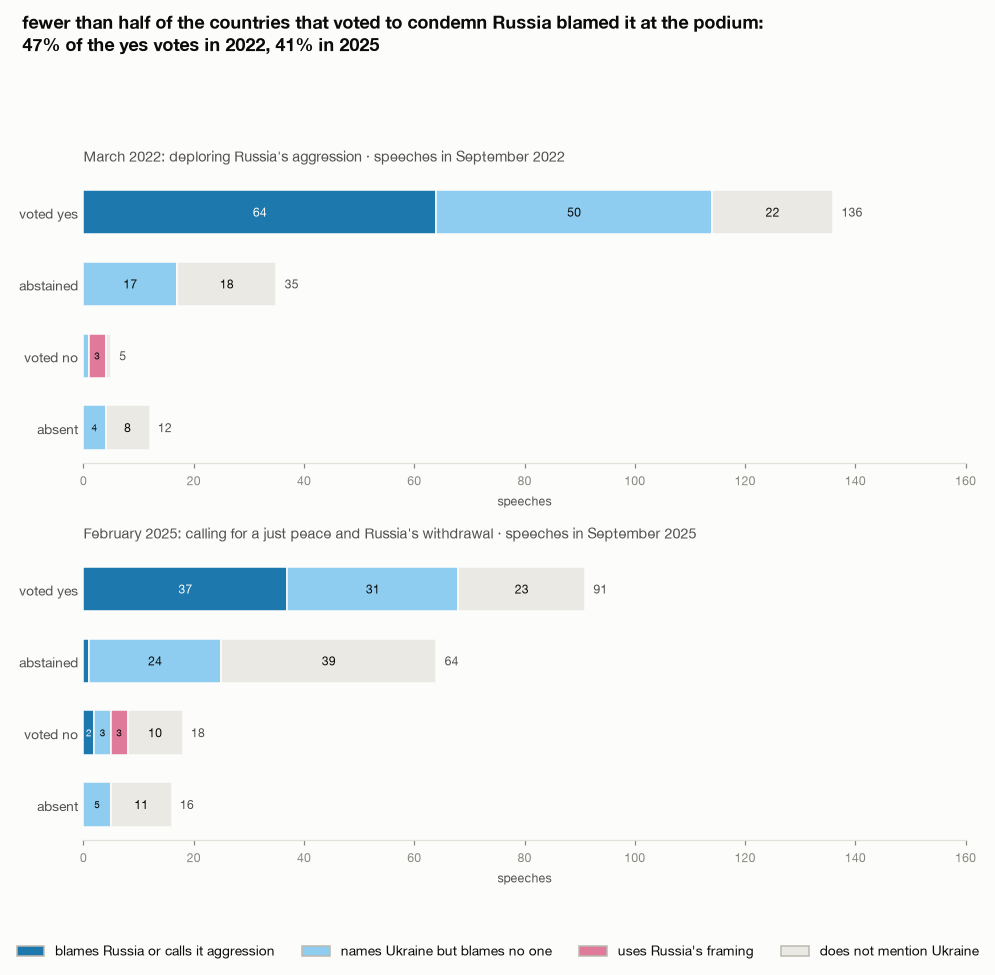

voted no in 2025 but blamed Russia that September: ['Marshall Islands', 'Palau'] 

2022: share of speeches blaming Russia, by vote: {'voted yes': '47% of 136', 'abstained': '0% of 35', 'voted no': '0% of 5', 'absent': '0% of 12'}
2025: share of speeches blaming Russia, by vote: {'voted yes': '41% of 91', 'abstained': '2% of 64', 'voted no': '11% of 18', 'absent': '0% of 16'}


In [9]:
VOTES = ["yes", "abstain", "no", "absent"]
VOTE_LABEL = {"yes": "voted yes", "abstain": "abstained", "no": "voted no", "absent": "absent"}
panels = [(2022, "ES-11/1", "March 2022: deploring Russia's aggression"), (2025, "ES-11/7", "February 2025: calling for a just peace and Russia's withdrawal")]

fig, axes = plt.subplots(2, 1, figsize=SQUARE)
summary = {}
for ax, (year, res, label) in zip(axes, panels):
    d = ukr[ukr.year == year].merge(votes[res].rename("vote"), left_on="iso3", right_index=True)
    share = pd.crosstab(d.vote, d.cls, normalize="index").reindex(index=VOTES, columns=list(UK), fill_value=0)
    n = d.vote.value_counts().reindex(VOTES, fill_value=0)
    summary[year] = (share, n)
    # bars are counts of speeches, on one scale for both votes, so a group of 10 does not look as large as a group of 150
    count = pd.crosstab(d.vote, d.cls).reindex(index=VOTES, columns=list(UK), fill_value=0)
    left = np.zeros(len(VOTES))
    for c in UK:
        ax.barh(range(len(VOTES)), count[c], left=left, color=UK[c], edgecolor=SURFACE, linewidth=1, height=0.62)
        for k, (l, v) in enumerate(zip(left, count[c])):
            if v >= 2:
                ax.text(l + v / 2, k, str(v), ha="center", va="center", fontsize=8 if v >= 6 else 6.5, color=SURFACE if c == BLAMES else INK)
        left += count[c].values
    for k, total in enumerate(left):
        ax.text(total + 1.5, k, str(int(total)), va="center", fontsize=8, color=INK_2)
    ax.set_yticks(range(len(VOTES)), [VOTE_LABEL[v] for v in VOTES], fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, 160); ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", labelsize=8)
    ax.set_xlabel("speeches", fontsize=8, color=INK_2)
    ax.spines["left"].set_visible(False)
    ax.set_title(f"{label} · speeches in September {year}", fontsize=9.5, fontweight="normal", color=INK_2)
yes22 = summary[2022][0].at["yes", BLAMES]
yes25 = summary[2025][0].at["yes", BLAMES]
fig.suptitle(f"fewer than half of the countries that voted to condemn Russia blamed it at the podium:\n"
             f"{yes22:.0%} of the yes votes in 2022, {yes25:.0%} in 2025", x=0.02, ha="left", fontweight="bold", fontsize=12)
legend(fig, [(c, UK[c]) for c in UK])
plt.tight_layout(rect=(0, 0.08, 1, 0.92)); show(fig, "w5_words_and_votes")

no25 = ukr[(ukr.year == 2025) & (ukr.cls == BLAMES)].merge(votes["ES-11/7"].rename("vote"), left_on="iso3", right_index=True)
print("voted no in 2025 but blamed Russia that September:", sorted(no25[no25.vote == "no"].delegation), "\n")
for year, (share, n) in summary.items():
    print(f"{year}: share of speeches blaming Russia, by vote:", {VOTE_LABEL[v]: f"{share.at[v, BLAMES]:.0%} of {n[v]}" for v in VOTES})

**who moved.** the countries that voted yes in 2022 and not in 2025, with the framing of their speech each year.

In [10]:
# the countries that voted yes in 2022 but not in 2025, with how they described the war in each year's speech
moved = votes[(votes["ES-11/1"] == "yes") & (votes["ES-11/7"] != "yes")].copy()
names = ref.dropna(subset=["iso3"]).drop_duplicates("iso3").set_index("iso3").name
for y in (2022, 2025, 2026):
    moved[f"speech {y}"] = moved.index.map(cls_in[y]).fillna("no speech on record")
moved.insert(0, "delegation", moved.index.map(names))
print(f"{len(moved)} countries voted yes in 2022 and did not in 2025:", moved["ES-11/7"].value_counts().to_dict())
moved.sort_values(["ES-11/7", "delegation"]).reset_index(drop=True)

48 countries voted yes in 2022 and did not in 2025: {'abstain': 35, 'no': 7, 'absent': 6}


resolution,delegation,ES-10/22,ES-10/23,ES-11/1,ES-11/7,speech 2022,speech 2025,speech 2026
0,Afghanistan,yes,absent,yes,absent,no speech on record,no speech on record,no speech on record
1,Benin,yes,yes,yes,absent,names Ukraine but blames no one,does not mention Ukraine,no speech on record
2,Democratic Republic of the Congo,yes,absent,yes,absent,names Ukraine but blames no one,names Ukraine but blames no one,does not mention Ukraine
3,Dominica,yes,yes,yes,absent,blames Russia or calls it aggression,does not mention Ukraine,does not mention Ukraine
4,Ecuador,yes,absent,yes,absent,blames Russia or calls it aggression,does not mention Ukraine,does not mention Ukraine
5,Georgia,abstain,abstain,yes,absent,blames Russia or calls it aggression,names Ukraine but blames no one,does not mention Ukraine
6,Argentina,abstain,no,yes,abstain,names Ukraine but blames no one,does not mention Ukraine,does not mention Ukraine
7,Bahrain,yes,yes,yes,abstain,does not mention Ukraine,does not mention Ukraine,names Ukraine but blames no one
8,Botswana,yes,yes,yes,abstain,blames Russia or calls it aggression,names Ukraine but blames no one,does not mention Ukraine
9,Brazil,yes,yes,yes,abstain,names Ukraine but blames no one,names Ukraine but blames no one,names Ukraine but blames no one


**Gaza.** [ES-10/22](https://undocs.org/A/RES/ES-10/22) in December 2023, demanding an immediate humanitarian ceasefire, and [ES-10/23](https://undocs.org/A/RES/ES-10/23) in May 2024, upgrading Palestine's rights at the UN, each against the speeches of September 2024, the first debate after both. there is no Gaza vote here after 2024: the later ones have no country-by-country table that can be checked. criticism of Israel is undercounted (see how well the rules read, at the end), so the pink and violet counts are a floor. the bars are counts of speeches, on one scale, so a group of 10 countries is drawn at its true size next to a group of 150.

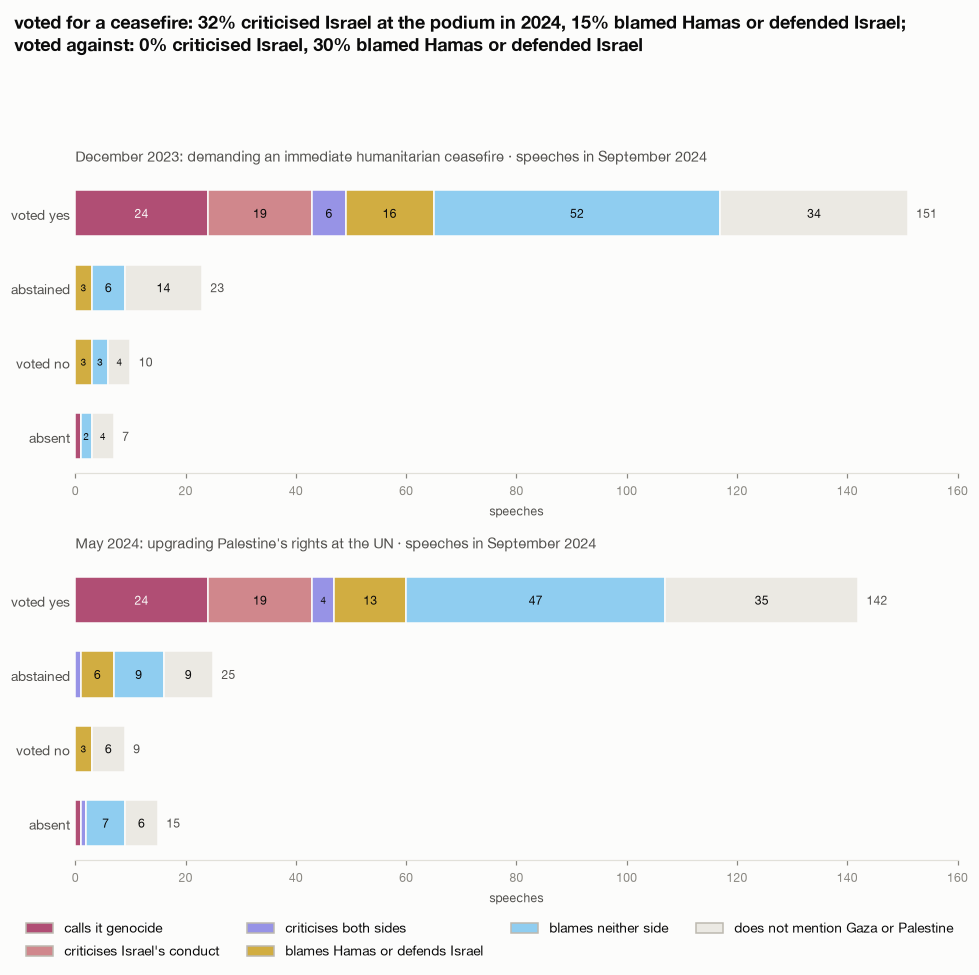

ES-10/22: share of 2024 speeches criticising Israel, by vote: {'voted yes': '32% of 151', 'abstained': '0% of 23', 'voted no': '0% of 10', 'absent': '14% of 7'}
ES-10/22: share blaming Hamas or defending Israel, by vote: {'voted yes': '15% of 151', 'abstained': '13% of 23', 'voted no': '30% of 10', 'absent': '0% of 7'}
  voted no (10): Austria: blames neither side; Czechia: does not mention Gaza or Palestine; Guatemala: blames neither side; Israel: blames Hamas or defends Israel; Liberia: blames neither side; Micronesia (Federated States of): blames Hamas or defends Israel; Nauru: does not mention Gaza or Palestine; Papua New Guinea: does not mention Gaza or Palestine; Paraguay: does not mention Gaza or Palestine; United States of America: blames Hamas or defends Israel 

ES-10/23: share of 2024 speeches criticising Israel, by vote: {'voted yes': '33% of 142', 'abstained': '4% of 25', 'voted no': '0% of 9', 'absent': '13% of 15'}
ES-10/23: share blaming Hamas or defending Israel, by vo

In [11]:
gaza_panels = [("ES-10/22", "December 2023: demanding an immediate humanitarian ceasefire"), ("ES-10/23", "May 2024: upgrading Palestine's rights at the UN")]
d24 = gz[gz.year == 2024]

fig, axes = plt.subplots(2, 1, figsize=SQUARE)
gaza_summary = {}
for ax, (res, label) in zip(axes, gaza_panels):
    d = d24.merge(votes[res].rename("vote"), left_on="iso3", right_index=True)
    share = pd.crosstab(d.vote, d.cls, normalize="index").reindex(index=VOTES, columns=list(GZ), fill_value=0)
    n = d.vote.value_counts().reindex(VOTES, fill_value=0)
    gaza_summary[res] = (share, n, d)
    # bars are counts of speeches, on one scale for both votes, so a group of 10 does not look as large as a group of 150
    count = pd.crosstab(d.vote, d.cls).reindex(index=VOTES, columns=list(GZ), fill_value=0)
    left = np.zeros(len(VOTES))
    for c in GZ:
        ax.barh(range(len(VOTES)), count[c], left=left, color=GZ[c], edgecolor=SURFACE, linewidth=1, height=0.62)
        for k, (l, v) in enumerate(zip(left, count[c])):
            if v >= 2:
                ax.text(l + v / 2, k, str(v), ha="center", va="center", fontsize=8 if v >= 6 else 6.5, color=SURFACE if c == GENOCIDE else INK)
        left += count[c].values
    for k, total in enumerate(left):
        ax.text(total + 1.5, k, str(int(total)), va="center", fontsize=8, color=INK_2)
    ax.set_yticks(range(len(VOTES)), [VOTE_LABEL[v] for v in VOTES], fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, 160); ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", labelsize=8)
    ax.set_xlabel("speeches", fontsize=8, color=INK_2)
    ax.spines["left"].set_visible(False)
    ax.set_title(f"{label} · speeches in September 2024", fontsize=9.5, fontweight="normal", color=INK_2)
ceasefire = gaza_summary["ES-10/22"][0]
fig.suptitle(f"voted for a ceasefire: {ceasefire.loc['yes', CRITICAL].sum():.0%} criticised Israel at the podium in 2024, "
             f"{ceasefire.loc['yes', SIDES].sum():.0%} blamed Hamas or defended Israel;\nvoted against: "
             f"{ceasefire.loc['no', CRITICAL].sum():.0%} criticised Israel, {ceasefire.loc['no', SIDES].sum():.0%} blamed Hamas or defended Israel",
             x=0.02, ha="left", fontweight="bold", fontsize=12)
legend(fig, [(c, GZ[c]) for c in GZ])
plt.tight_layout(rect=(0, 0.06, 1, 0.92)); show(fig, "w6_gaza_words_and_votes")

for res, (share, n, d) in gaza_summary.items():
    print(f"{res}: share of 2024 speeches criticising Israel, by vote:", {VOTE_LABEL[v]: f"{share.loc[v, CRITICAL].sum():.0%} of {n[v]}" for v in VOTES})
    print(f"{res}: share blaming Hamas or defending Israel, by vote:", {VOTE_LABEL[v]: f"{share.loc[v, SIDES].sum():.0%} of {n[v]}" for v in VOTES})
    against = d[d.vote == "no"].sort_values("delegation")
    print(f"  voted no ({len(against)}):", "; ".join(f"{r.delegation}: {r.cls}" for r in against.itertuples()), "\n")
print(f"for comparison, Ukraine: {summary[2022][0].at['yes', BLAMES]:.0%} of the countries that voted to condemn Russia in March 2022 blamed it that September")

## caveats

- **rules, not readers.** the framings come from word patterns. they miss criticism in unusual words, and can mistake a quoted accusation or someone else's aggression for the speaker's own. the evidence sentence is kept so any label can be checked, and the blind check below measures how often they are wrong.
- **strongest framing only.** a speech that blames Russia and also calls for talks is counted as blaming Russia.
- **the texts change kind** between years, as noted at the top.
- **one sentence decides.** a single strong sentence is enough for a label, however long the rest of the speech.
- **the two wars are read on different scales**, as noted at the top: compare each war with itself more than with the other.
- **the checks were made by AI models, working to definitions written here.** agreement shows the rules match those definitions, not that the definitions are neutral. a sheet of 40 unseen speeches in [`notebooks/human_check/`](https://github.com/jeremychia/unga-speeches/tree/main/notebooks/human_check) is ready for a person to label; the last cell of this notebook scores it once it is filled in.

## how well the rules read

each sample was labelled blind, from the extracted sentences alone, by a reader that never saw the rules (a separate AI model each time, not a person). the samples are listed in [`analysis/wording_check.py`](https://github.com/jeremychia/unga-speeches/blob/main/src/unga_speeches/analysis/wording_check.py), which also redraws them and rebuilds the passages the readers saw; the labels are in [`tests/fixtures/wording_blind_labels.csv`](https://github.com/jeremychia/unga-speeches/blob/main/tests/fixtures/wording_blind_labels.csv). the **review**, **holdout** and **full 2026** samples were each used to correct the rules after they were scored, so their scores now flatter the rules. the **final** sample was drawn after the last correction from speeches no reader had seen, and the rules were not changed after it was scored: it is the fair measure.

**what it shows.** on the final sample, the rules and the reader agree on 39 of 40 Ukraine speeches: every speech the rules say blames Russia does, and they catch 18 of the 19 that do. for Gaza they agree on 29 of 40. every speech the rules call critical of Israel is, but they catch only 11 of the 20 the reader found critical, mostly implicit criticism such as "a collective punishment of the entire Palestinian people" or "the interruption of water, food and energy supplies" with no actor named. on the second Gaza question, written after the first three checks and before any reader labelled it, every speech the rules say blames Hamas or defends Israel does, and they catch 12 of the 17 the reader found (11 before a fix drawn from the 2026 readings, not from this sample). so the Ukraine counts and the genocide counts can be read as they stand; the counts of criticism of Israel are a floor, too low by about half in 2024 and 2025. for 2026, where a reader labelled every speech, the rules agree on 105 of 109.

**one change after the final sample.** building the Gaza vote chart showed that Israel's own 2024 and 2025 speeches were labelled as criticising Israel: one sentence had Hamas attacking Israel, one quoted the accusation to deny it. the rules now skip sentences where Israel's attackers are named first, or the act is "of 7 October", or Israel "is accused of" it. on the final sample this costs one correct call (Brazil, whose criticism was only caught by accident), which is why its Gaza score reads 29 rather than 30; implicit criticism like Brazil's was not added afterwards, so the sample stays a fair measure.

In [12]:
from unga_speeches.analysis import wording_check

labels = pd.read_csv(ROOT / "tests/fixtures/wording_blind_labels.csv")
print(wording_check.score(labels, classified).to_string(index=False), "\n")
final = labels[labels["sample"] == "final"].merge(classified, on=["year", "iso3"], suffixes=("", "_rules"))
d = final[final.war == "ukraine"]
print("final sample, ukraine: rows are the blind label, columns the rules"); print(pd.crosstab(d.label, d.ukraine).to_string(), "\n")
d = final[final.war == "gaza"]
print("final sample, criticism of Israel: rows are the blind label, columns the rules")
print(pd.crosstab(d.label, d.gaza.map(wording_check.CRITICISM)).to_string(), "\n")
print("final sample, blames Hamas or defends Israel: rows are the blind label, columns the rules")
print(pd.crosstab(d.israels_side.astype(bool), d.israels_side_rules.astype(bool)).to_string(), "\n")

# a person's labels, once the sheet in notebooks/human_check/ is filled in
human = wording_check.read_human(ROOT / "notebooks/human_check/labels.csv")
print(wording_check.score(human, classified).to_string(index=False) if len(human) else "the human check sheet has not been filled in yet")

   sample                       question  speeches  agree rules say yes, reader agrees reader says yes, rules catch
   review                  blames Russia        40     39                     22 of 22                     22 of 23
   review              criticises Israel        40     37                     17 of 19                     17 of 18
  holdout                  blames Russia        30     26                       8 of 9                      8 of 11
  holdout              criticises Israel        30     26                     14 of 14                     14 of 17
full 2026                  blames Russia        81     81                     39 of 39                     39 of 39
full 2026              criticises Israel       109    105                     44 of 44                     44 of 47
full 2026 blames Hamas or defends Israel       109    107                     19 of 19                     19 of 21
    final                  blames Russia        40     39               